# 07 – Beispielvorhersage: Alle Modelle im Vergleich

**Bedienung:** Nur `ENGINE_ID` in der ersten Code-Zelle ändern und alles durchlaufen lassen.

```python
ENGINE_ID = 3              # Eine einzelne Engine
ENGINE_ID = [3, 15, 46]    # Mehrere Engines (bis ~15 als Balken)
ENGINE_ID = list(range(1, 101))  # Alle Engines (sortierte Übersicht)
```

**Datenquelle:** `ml/reports/predictions_test.csv`. Die Datei wird von den Notebooks 03 (RF), 04 (XGBoost), 05 (SVR) und 08 (BiLSTM) geschrieben.  
Es sind also exakt die getunten Modelle aus der Vergleichstabelle in Notebook 06. Hier wird nichts neu trainiert,  
deshalb stimmen die Zahlen pro Engine mit den Gesamtmetriken überein.

In [1]:
# ══════════════════════════════════════════════════
# NUR DIESE VARIABLE ÄNDERN – dann alles ausführen
# Gültige Werte: 1 bis 100
ENGINE_ID = [3, 15, 46, 72, 88]

# Weitere Beispiele:
# ENGINE_ID = 46
# Top-Engines (Notebook 08):   [1, 4, 11, 14, 24, 39, 40, 48, 56, 97]
# Worst-Engines (Notebook 08): [2, 16, 19, 54, 58, 62, 70, 89, 93, 96]
# Alle 100 Engines:            list(range(1, 101))
# ══════════════════════════════════════════════════

In [2]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from src.evaluation.metrics import evaluate_all, compare_models
from src.evaluation.results import load_predictions, load_results, MODEL_ORDER
from src.config import REPORTS

sns.set_theme(style='whitegrid')
REPORTS.mkdir(parents=True, exist_ok=True)

# ENGINE_ID normalisieren: immer eine Liste
ENGINE_IDS = [ENGINE_ID] if isinstance(ENGINE_ID, int) else list(ENGINE_ID)
print(f'Setup fertig. {len(ENGINE_IDS)} Engine(s): {ENGINE_IDS[:15]}{" …" if len(ENGINE_IDS) > 15 else ""}')

Setup fertig. 5 Engine(s): [3, 15, 46, 72, 88]


In [3]:
preds = load_predictions()
MODELS = [m for m in MODEL_ORDER if m in preds.columns]
SHORT  = {'Random Forest': 'RF', 'XGBoost': 'XGBoost', 'SVR (RBF)': 'SVR', 'BiLSTM + Attention': 'BiLSTM'}
MODEL_COLORS = {'RF': '#4472C4', 'XGBoost': '#ED7D31', 'SVR': '#70AD47', 'BiLSTM': '#9B59B6'}

invalid = [e for e in ENGINE_IDS if e not in preds.index]
assert not invalid, f'Engine(s) {invalid} nicht im Testset. Gültig: 1–100'

print(f'Vorhersagen geladen für {len(preds)} Engines, Modelle: {MODELS}')
for eid in ENGINE_IDS[:15]:
    print(f'  Engine {eid:3d} → Wahre RUL: {int(preds.loc[eid, "RUL_true"])} Zyklen')

Vorhersagen geladen für 100 Engines, Modelle: ['Random Forest', 'XGBoost', 'SVR (RBF)', 'BiLSTM + Attention']
  Engine   3 → Wahre RUL: 27 Zyklen
  Engine  15 → Wahre RUL: 108 Zyklen
  Engine  46 → Wahre RUL: 7 Zyklen
  Engine  72 → Wahre RUL: 45 Zyklen
  Engine  88 → Wahre RUL: 144 Zyklen


## Vorhersagen pro Engine

Δ = Vorhersage − wahre RUL. **Δ > 0** heißt zu optimistisch (Ausfall kommt früher als vorhergesagt), **Δ < 0** heißt zu pessimistisch.

In [4]:
records = []
for eid in ENGINE_IDS:
    true_rul = int(preds.loc[eid, 'RUL_true'])
    row = {'Engine': eid, 'Wahre RUL': true_rul}
    for m in MODELS:
        p = float(preds.loc[eid, m])
        row[SHORT[m]]         = round(p, 1)
        row[f'Δ {SHORT[m]}']  = round(p - true_rul, 1)
    row['Bestes Modell'] = min((SHORT[m] for m in MODELS), key=lambda s: abs(row[f'Δ {s}']))
    records.append(row)

df_results = pd.DataFrame(records).set_index('Engine')
short_models = [SHORT[m] for m in MODELS]

print('=== Vorhersagen ===')
print(df_results[['Wahre RUL'] + short_models + [f'Δ {s}' for s in short_models] + ['Bestes Modell']].to_string())

=== Vorhersagen ===
        Wahre RUL     RF  XGBoost    SVR  BiLSTM  Δ RF  Δ XGBoost  Δ SVR  Δ BiLSTM Bestes Modell
Engine                                                                                          
3              27   31.3     34.5   32.0    33.2   4.3        7.5    5.0       6.2            RF
15            108  118.1    114.4  116.4   120.2  10.1        6.4    8.4      12.2       XGBoost
46              7   15.9     17.8   17.0     7.6   8.9       10.8   10.0       0.6        BiLSTM
72             45   64.5     60.1   74.1    50.9  19.5       15.1   29.1       5.9        BiLSTM
88            144  122.6    121.4  123.5   123.0 -21.4      -22.6  -20.5     -21.0           SVR


## Visualisierung

Plot gespeichert: example_prediction_engines_3_15_46_72_88.png


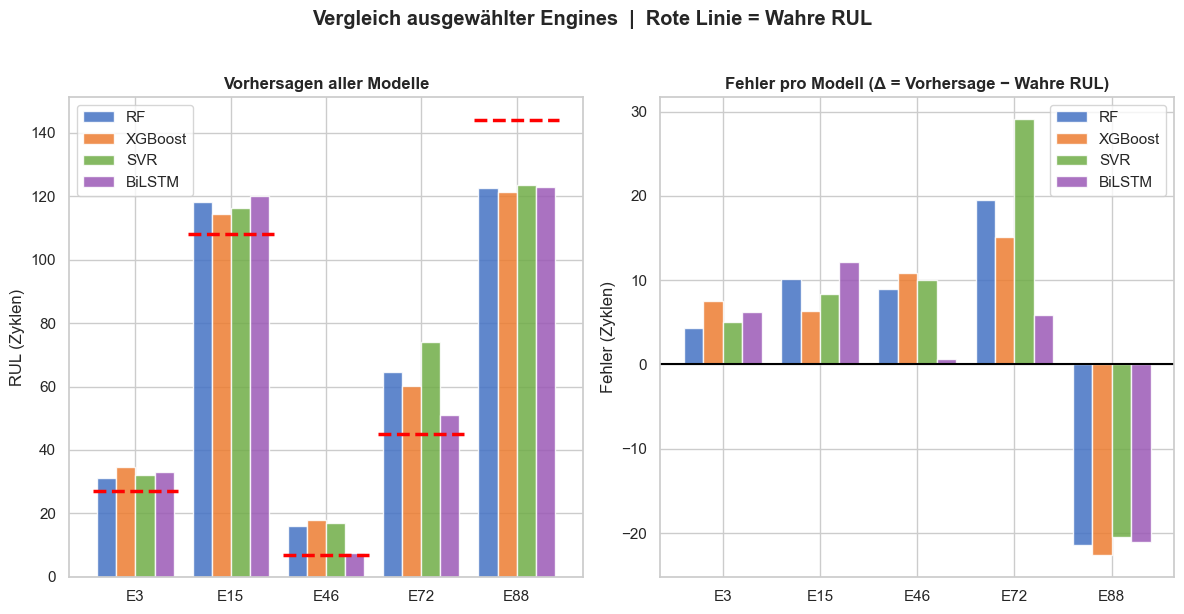

In [5]:
n_engines = len(ENGINE_IDS)
n_models  = len(short_models)

if n_engines == 1:
    # ── Einzelne Engine: Balken + Fehler ─────────────────────────────────────
    eid = ENGINE_IDS[0]
    row = df_results.loc[eid]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    ax = axes[0]
    vals = [row[s] for s in short_models]
    bars = ax.bar(short_models, vals, color=[MODEL_COLORS[s] for s in short_models],
                  alpha=0.85, width=0.5, zorder=3)
    ax.axhline(y=row['Wahre RUL'], color='red', linewidth=2.5, linestyle='--',
               label=f'Wahre RUL = {row["Wahre RUL"]} Zyklen')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
                f'{v:.0f}', ha='center', fontweight='bold', fontsize=11)
    ax.set_title(f'Vorhersagen – Engine {eid}', fontweight='bold')
    ax.set_ylabel('RUL (Zyklen)')
    ax.set_ylim(0, max(max(vals), row['Wahre RUL']) * 1.25)
    ax.legend(); ax.set_axisbelow(True)

    ax2 = axes[1]
    errors = [row[f'Δ {s}'] for s in short_models]
    ax2.bar(short_models, errors, color=['#c00000' if e > 0 else '#4472C4' for e in errors],
            alpha=0.85, width=0.5, zorder=3)
    ax2.axhline(y=0, color='black', linewidth=1.5)
    for i, err in enumerate(errors):
        ax2.text(i, err + 0.5 if err >= 0 else err - 2.5, f'{err:+.0f}',
                 ha='center', fontweight='bold', fontsize=11)
    ax2.set_title('Fehler (Δ = Vorhersage − Wahre RUL)', fontweight='bold')
    ax2.set_ylabel('Fehler (Zyklen)')
    ax2.legend(handles=[mpatches.Patch(color='#c00000', alpha=0.85, label='Zu optimistisch (Δ > 0)'),
                        mpatches.Patch(color='#4472C4', alpha=0.85, label='Zu pessimistisch (Δ < 0)')],
               fontsize=9)
    ax2.set_axisbelow(True)
    plt.suptitle(f'Engine {eid}  |  Wahre RUL: {row["Wahre RUL"]} Zyklen  |  Bestes Modell: {row["Bestes Modell"]}',
                 fontweight='bold', y=1.02)

elif n_engines <= 15:
    # ── Bis 15 Engines: gruppierte Balken (Breite begrenzt) ───────────────────
    fig, axes = plt.subplots(1, 2, figsize=(min(max(12, 1.8 * n_engines), 26), 6))
    x      = np.arange(n_engines)
    width  = 0.8 / n_models
    shifts = (np.arange(n_models) - (n_models - 1) / 2) * width
    labels = [f'E{eid}' for eid in ENGINE_IDS]

    for ax, prefix, title in [(axes[0], '',   'Vorhersagen aller Modelle'),
                              (axes[1], 'Δ ', 'Fehler pro Modell (Δ = Vorhersage − Wahre RUL)')]:
        for s, dx in zip(short_models, shifts):
            ax.bar(x + dx, df_results[prefix + s], width, label=s, color=MODEL_COLORS[s], alpha=0.85)
        ax.set_title(title, fontweight='bold')
        ax.set_xticks(x); ax.set_xticklabels(labels)
        ax.legend(); ax.set_axisbelow(True)
    for i, eid in enumerate(ENGINE_IDS):
        t = df_results.loc[eid, 'Wahre RUL']
        axes[0].plot([i - 0.45, i + 0.45], [t, t], color='red', linewidth=2.5, linestyle='--')
    axes[0].set_ylabel('RUL (Zyklen)')
    axes[1].axhline(y=0, color='black', linewidth=1.5)
    axes[1].set_ylabel('Fehler (Zyklen)')
    plt.suptitle('Vergleich ausgewählter Engines  |  Rote Linie = Wahre RUL', fontweight='bold', y=1.02)

else:
    # ── Viele Engines: nach wahrer RUL sortierte Übersicht ────────────────────
    d = df_results.sort_values('Wahre RUL')
    x = np.arange(len(d))
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    axes[0].plot(x, d['Wahre RUL'], color='red', linewidth=2.5, label='Wahre RUL')
    for s in short_models:
        axes[0].scatter(x, d[s], s=14, color=MODEL_COLORS[s], alpha=0.75, label=s)
        axes[1].scatter(d['Wahre RUL'], d[f'Δ {s}'], s=14, color=MODEL_COLORS[s], alpha=0.75, label=s)
    axes[0].set_title(f'{len(d)} Engines, sortiert nach wahrer RUL', fontweight='bold')
    axes[0].set_xlabel('Engine (sortiert)'); axes[0].set_ylabel('RUL (Zyklen)'); axes[0].legend()
    axes[1].axhline(0, color='black', linewidth=1.5)
    axes[1].axvline(125, color='grey', linestyle=':', label='RUL-Cap 125')
    axes[1].set_title('Fehler vs. wahre RUL', fontweight='bold')
    axes[1].set_xlabel('Wahre RUL (Zyklen)'); axes[1].set_ylabel('Δ = Vorhersage − Wahre RUL'); axes[1].legend()

plt.tight_layout()
label = (f'engine_{ENGINE_IDS[0]}' if n_engines == 1 else
         f'engines_{"_".join(map(str, ENGINE_IDS))}' if n_engines <= 6 else
         f'{n_engines}_engines')
save_path = REPORTS / f'example_prediction_{label}.png'
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot gespeichert: {save_path.name}')

In [6]:
# Kontrolle: Gesamtmetriken aus den gespeicherten Vorhersagen (alle 100 Engines)
all_results = compare_models([
    evaluate_all(preds['RUL_true'].values, preds[m].values, m) for m in MODELS
])
print('=== Vollständige Test-Set Evaluation (alle 100 Engines) ===')
print(all_results.to_string())

# Muss exakt mit model_results.json übereinstimmen (gleiche Modelle, gleiche Vorhersagen)
stored = pd.DataFrame(load_results()).T[['RMSE', 'MAE', 'R²', 'NASA Score']].astype(float)
diff = (all_results[stored.columns] - stored.loc[all_results.index]).abs().max().max()
print(f'\nMax. Abweichung zu model_results.json: {diff:.3f}')
print('→ Einzelne Engines können vom Gesamtdurchschnitt deutlich abweichen.')

=== Vollständige Test-Set Evaluation (alle 100 Engines) ===
                     RMSE    MAE     R²  NASA Score
Model                                              
BiLSTM + Attention  13.33  10.05  0.896       265.4
XGBoost             20.45  15.21  0.756      1801.4
Random Forest       20.66  15.36  0.751      2011.9
SVR (RBF)           21.12  15.73  0.740      1809.1

Max. Abweichung zu model_results.json: 0.000
→ Einzelne Engines können vom Gesamtdurchschnitt deutlich abweichen.
